CD704: Exercises, Week 4
27 October 2026


You may need LLM / AI help for the following exercises.


# Exercise 1 (Multicollinearity and Coefficients under Regularisation). 

Consider the synthetic dataset used in the lecture, with the model $y = 3x_1 + 2x_2 + 1$ and a spurious third
feature $x_{new} = 7x_1 − 5x_2 + \text{noise}$.
1. Fit a standard linear regression model using $x_1$, $x_2$, and $x_{new}$ and print the coefficients
$w_1$, $w_2$, and $w_{new}$.
2. Fit a ridge regression model and a LASSO model starting with $\alpha = 1.0$. How do
the coefficients change compared to the standard linear regression?
3. Fit a ridge model for values of $\alpha$ spaced evenly on a logarithmic scale between $10^{−3}$
and $10^3$ and plot the three coefficients against $\alpha$ (using a logarithmic scale, as in
the lecture).
4. Repeat the previous step for LASSO. Compare the trajectories of the coefficients
in the two plots.

## Response

Let us start by constructing our synthetic dataset...

### Constructing the Synthetic Dataset

In [1]:
from pathlib import Path
import sys

# Find the repository root from the notebook's current directory
project_root = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "utils").is_dir()
)

sys.path.insert(0, str(project_root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from utils.sklearn_helpers import split_data
from sklearn.linear_model import LinearRegression

np.random.seed(112358)
n_samples = 50
x_1 = np.random.normal(0, 1, n_samples)
x_2 = np.random.normal(0, 1, n_samples)
x_new = 7*x_1 - 5*x_2 + np.random.normal(0, 1, n_samples)
y = 3 * x_1 + 2 * x_2 + 1 + np.random.normal(0, 1, n_samples)
y_exact = 3 * x_1 + 2 * x_2 + 1

### Run a Linear Regression

In [3]:
X_base = np.column_stack((x_1, x_2, x_new))
lr_base = LinearRegression().fit(X_base, y)

# Print the coefficients and intercept of the base model
print("Base Model Coefficients:", lr_base.coef_)
print("Base Model Intercept:", lr_base.intercept_)

Base Model Coefficients: [ 4.31976125  1.03954997 -0.18993799]
Base Model Intercept: 0.8362176316085131


The Base Model Coefficients above are the weights ($w_i$).

### Run LASSO and Ridge Regressions

We're going to fit LASSO and Ridge models next and compare the coefficients.

In [4]:
from sklearn.linear_model import Lasso, Ridge
    
ridge_base = Ridge(alpha=1.0).fit(X_base, y)
lasso_base = Lasso(alpha=1.0).fit(X_base, y)

# Print the coefficients and intercept of the LASSO and
# Ridge models
print("Ridge Model Coefficients:", ridge_base.coef_)
print("Ridge Model Intercept:", ridge_base.intercept_)
print("LASSO Model Coefficients:", lasso_base.coef_)
print("LASSO Model Intercept:", lasso_base.intercept_)

# ... And the base model coefficients and intercept
print("Base Model Coefficients:", lr_base.coef_)
print("Base Model Intercept:", lr_base.intercept_)

Ridge Model Coefficients: [2.77751698 2.05192774 0.02234808]
Ridge Model Intercept: 0.8171834081238569
LASSO Model Coefficients: [0.         2.49276954 0.29104332]
LASSO Model Intercept: 0.8511114659186442
Base Model Coefficients: [ 4.31976125  1.03954997 -0.18993799]
Base Model Intercept: 0.8362176316085131


### Run $\alpha$-parameterised LASSO and Ridge Regressions

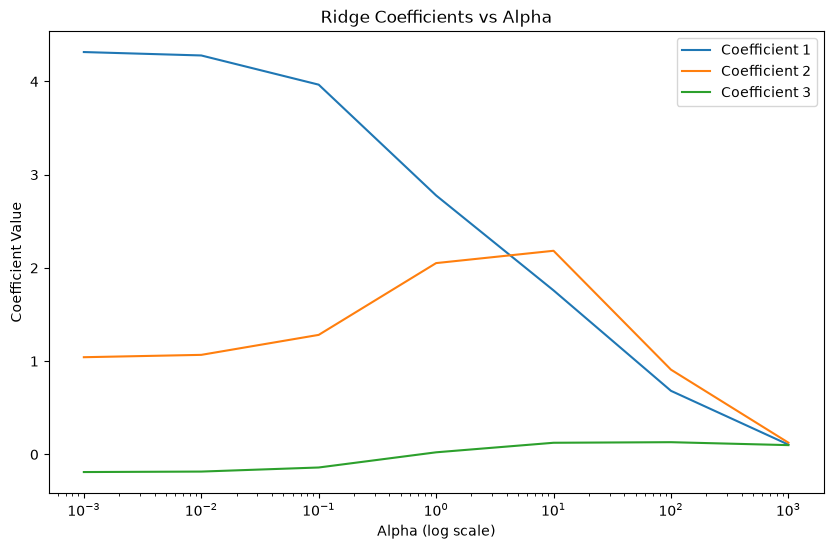

In [5]:
x_vals = []
y_vals = []
for i in range(-3, 4):
    alpha = 10 ** i
    ridge_model = Ridge(alpha=alpha).fit(X_base, y)
    x_vals.append(alpha)
    y_vals.append(ridge_model.coef_)

# Plot the coefficients of the Ridge model for different alpha values
plt.figure(figsize=(10, 6))
for i in range(len(y_vals[0])):
    plt.plot(x_vals, [y[i] for y in y_vals], label=f'Coefficient {i+1}')
    
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Coefficient Value')
plt.title('Ridge Coefficients vs Alpha')
plt.legend()
plt.show()


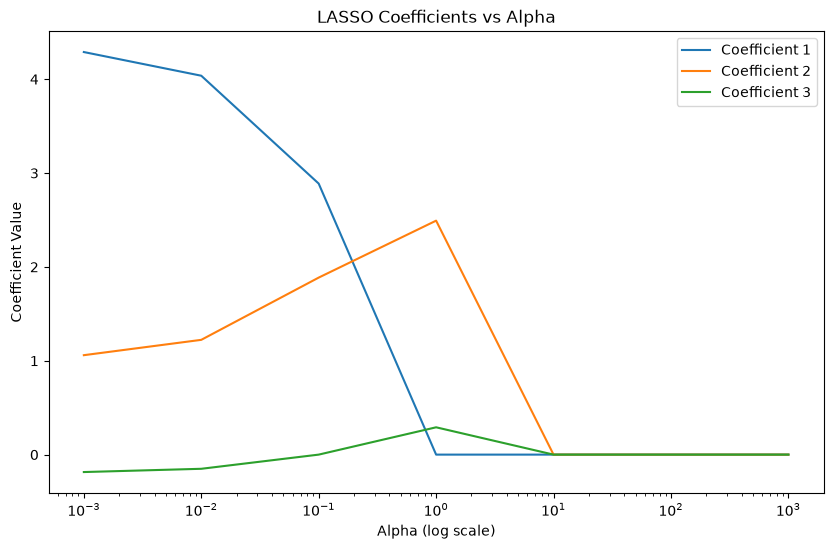

In [6]:
x_vals = []
y_vals = []
for i in range(-3, 4):
    alpha = 10 ** i
    lasso_model = Lasso(alpha=alpha).fit(X_base, y)
    x_vals.append(alpha)
    y_vals.append(lasso_model.coef_)

# Plot the coefficients of the LASSO model for different alpha values
plt.figure(figsize=(10, 6))
for i in range(len(y_vals[0])):
    plt.plot(x_vals, [y[i] for y in y_vals], label=f'Coefficient {i+1}')
    
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Coefficient Value')
plt.title('LASSO Coefficients vs Alpha')
plt.legend()
plt.show()





# Exercise 2 (Overfitting Management). 

In Exercise 3(d) from Week 3, a quadratic polynomial transformation led to overfitting. Now your goal is to use regularised methods in
the same setup.

1. Fit a ridge regression model for different values of $\alpha$ to find one that improves the test $R^2$ significantly.

2. Repeat the previous step for LASSO. Check how many coefficients are exactly 0.0.

3. For your ridge and LASSO models, extract the names of the top 5 features with
the largest absolute coefficients. Do these selected features and interactions make
sense?

4. Fit the StandardScaler on the training data only, then transform both training
and test sets using the scaler. Repeat all the steps above and note how the results
change. Can you explain what happens?

## Response

### A Diabetes Reminder...

In [7]:
# Load the scikit-learn Diabetes dataset and split it into training and test sets.
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit a linear regression model to the training data and evaluate its performance on the test data.
lr = LinearRegression().fit(X_train, y_train)
y_pred = lr.predict(X_test)
print("Linear Regression R-squared:", lr.score(X_test, y_test))

# Fit a polynomial regression model to the training data and evaluate its performance on the test data.
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
poly_lr = LinearRegression().fit(X_train_poly, y_train)
y_train_poly_pred = poly_lr.predict(X_train_poly)
y_test_poly_pred = poly_lr.predict(X_test_poly)

print("Polynomial Training R-squared:", poly_lr.score(X_train_poly, y_train))
print("Polynomial Test R-squared:", poly_lr.score(X_test_poly, y_test))


Linear Regression R-squared: 0.45260276297191926
Polynomial Training R-squared: 0.6061583502354682
Polynomial Test R-squared: 0.415639933640801


### Fitting a Ridge Regression Model on the Diabetes Data

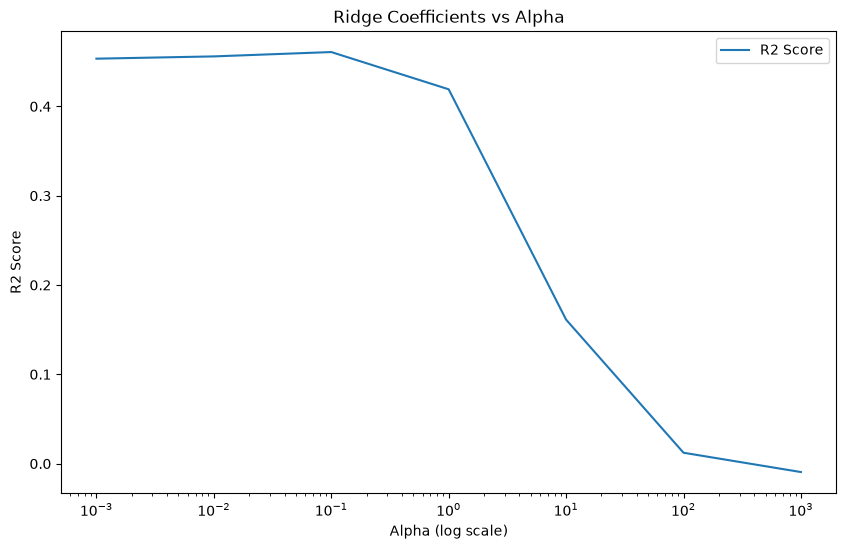

In [8]:
diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

x_vals = []
y_vals = []
for i in range(-3, 4):
    alpha = 10 ** i
    ridge_model = Ridge(alpha=alpha).fit(X_train, y_train)
    x_vals.append(alpha)
    # Get the R-squared score of the Ridge model on the test data
    r2_score = ridge_model.score(X_test, y_test)
    y_vals.append(r2_score)

# Plot the R-squared scores of the Ridge model for different alpha values
plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, label=f'R2 Score')
    
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('R2 Score')
plt.title('Ridge Coefficients vs Alpha')
plt.legend()
plt.show()


### Fitting a LASSO Regression to the Diabetes Data

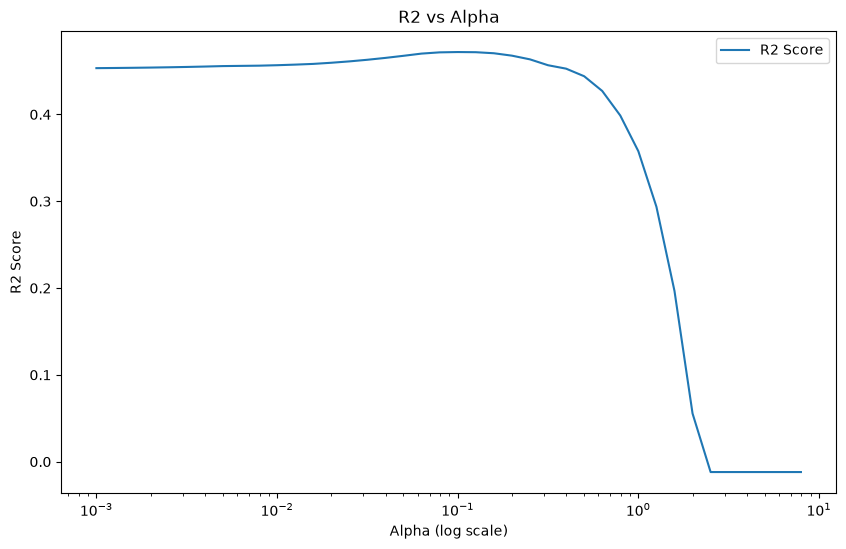

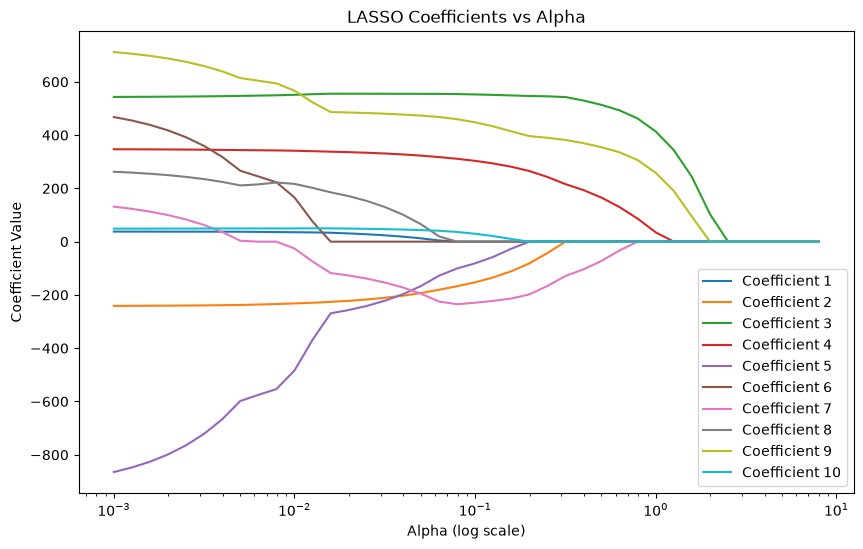

In [34]:
diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

x_vals = []
r2_vals = []
y_vals = []
for i in range(-30, 10, 1):
    alpha = 10 ** (i/10)
    lasso_model = Lasso(alpha=alpha).fit(X_train, y_train)
    x_vals.append(alpha)
    # Get the R-squared score of the Lasso model on the test data
    r2_score = lasso_model.score(X_test, y_test)
    r2_vals.append(r2_score)
    y_vals.append(lasso_model.coef_)

# Plot the R-squared scores of the Lasso model for different alpha values
plt.figure(figsize=(10, 6))
plt.plot(x_vals, r2_vals, label=f'R2 Score')
    
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('R2 Score')
plt.title('R2 vs Alpha')
plt.legend()
plt.show()

# Plot the coefficients of the LASSO model for different alpha values
plt.figure(figsize=(10, 6))
for i in range(len(y_vals[0])):
    plt.plot(x_vals, [y[i] for y in y_vals], label=f'Coefficient {i+1}')
    
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Coefficient Value')
plt.title('LASSO Coefficients vs Alpha')
plt.legend()
plt.show()


/Users/swerdna/Library/CloudStorage/GoogleDrive-swerdna.neb@gmail.com/My Drive/Brighton/University of Brighton/MSc Data Analytics/CD704 Machine Learning/CD704-ML/.venv/lib/python3.15/site-packages/sklearn/base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)


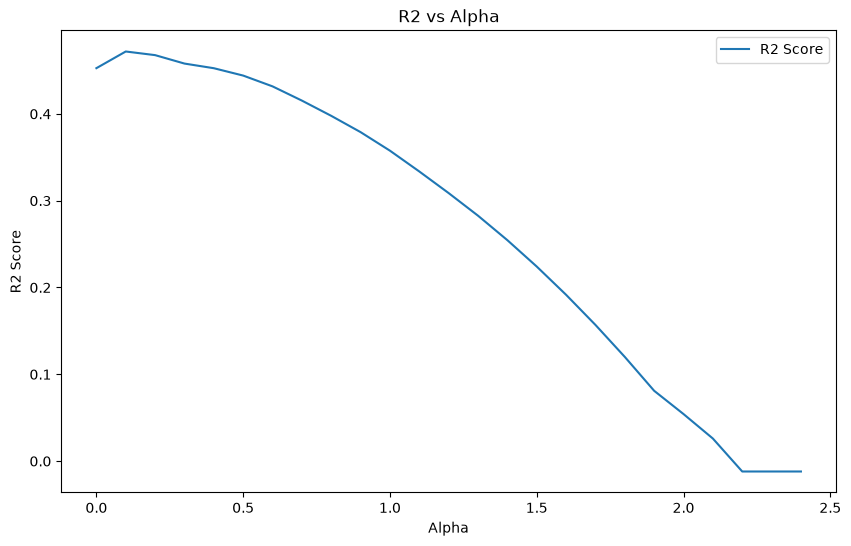

<Figure size 640x480 with 0 Axes>

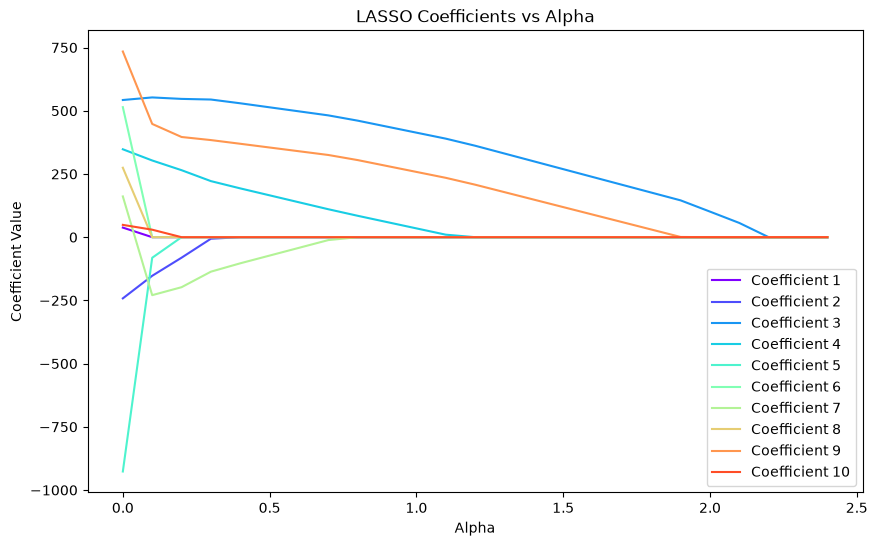

In [10]:
diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

x_vals = []
r2_vals = []
y_vals = []
for i in range(0, 25, 1):
    alpha = i/10
    lasso_model = Lasso(alpha=alpha).fit(X_train, y_train)
    x_vals.append(alpha)
    # Get the R-squared score of the Lasso model on the test data
    r2_score = lasso_model.score(X_test, y_test)
    r2_vals.append(r2_score)
    y_vals.append(lasso_model.coef_)

# Plot the R-squared scores of the Lasso model for different alpha values
plt.figure(figsize=(10, 6))
plt.plot(x_vals, r2_vals, label=f'R2 Score')
    
plt.xlabel('Alpha')
plt.ylabel('R2 Score')
plt.title('R2 vs Alpha')
plt.legend()
plt.show()

# Plot the coefficients of the LASSO model for different alpha values
# Set the color map to 'rainbow' for better visualization
plt.set_cmap('rainbow')
plt.figure(figsize=(10, 6))
for i in range(len(y_vals[0])):
    plt.plot(x_vals, [y[i] for y in y_vals], label=f'Coefficient {i+1}', color=plt.cm.rainbow(i/len(y_vals[0])))
    
plt.xlabel('Alpha')
plt.ylabel('Coefficient Value')
plt.title('LASSO Coefficients vs Alpha')
plt.legend()
plt.show()


### Considering the Variables with the Largest Coefficients

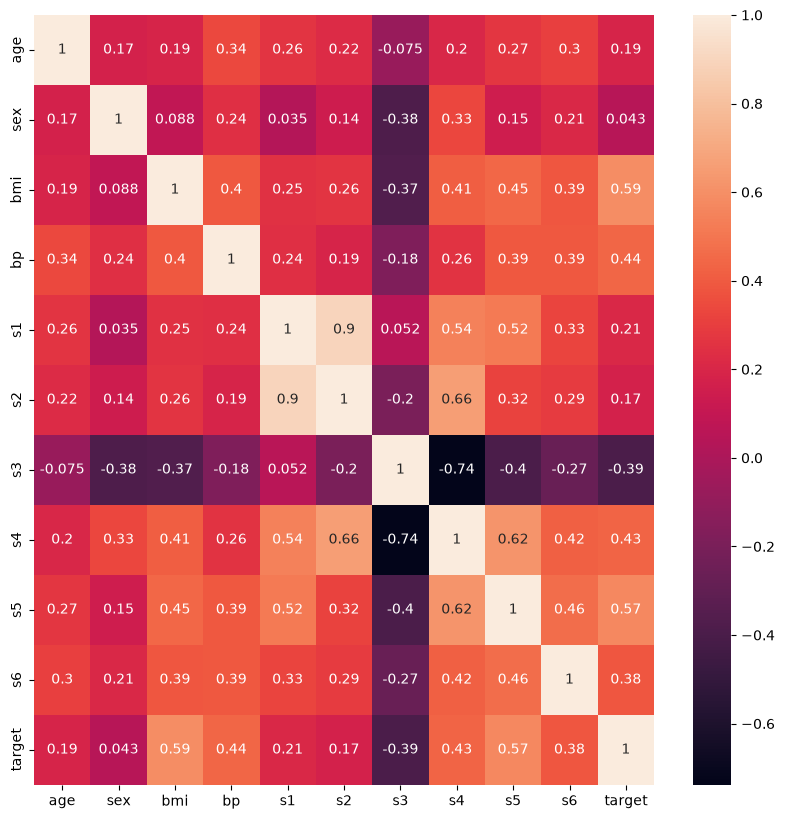

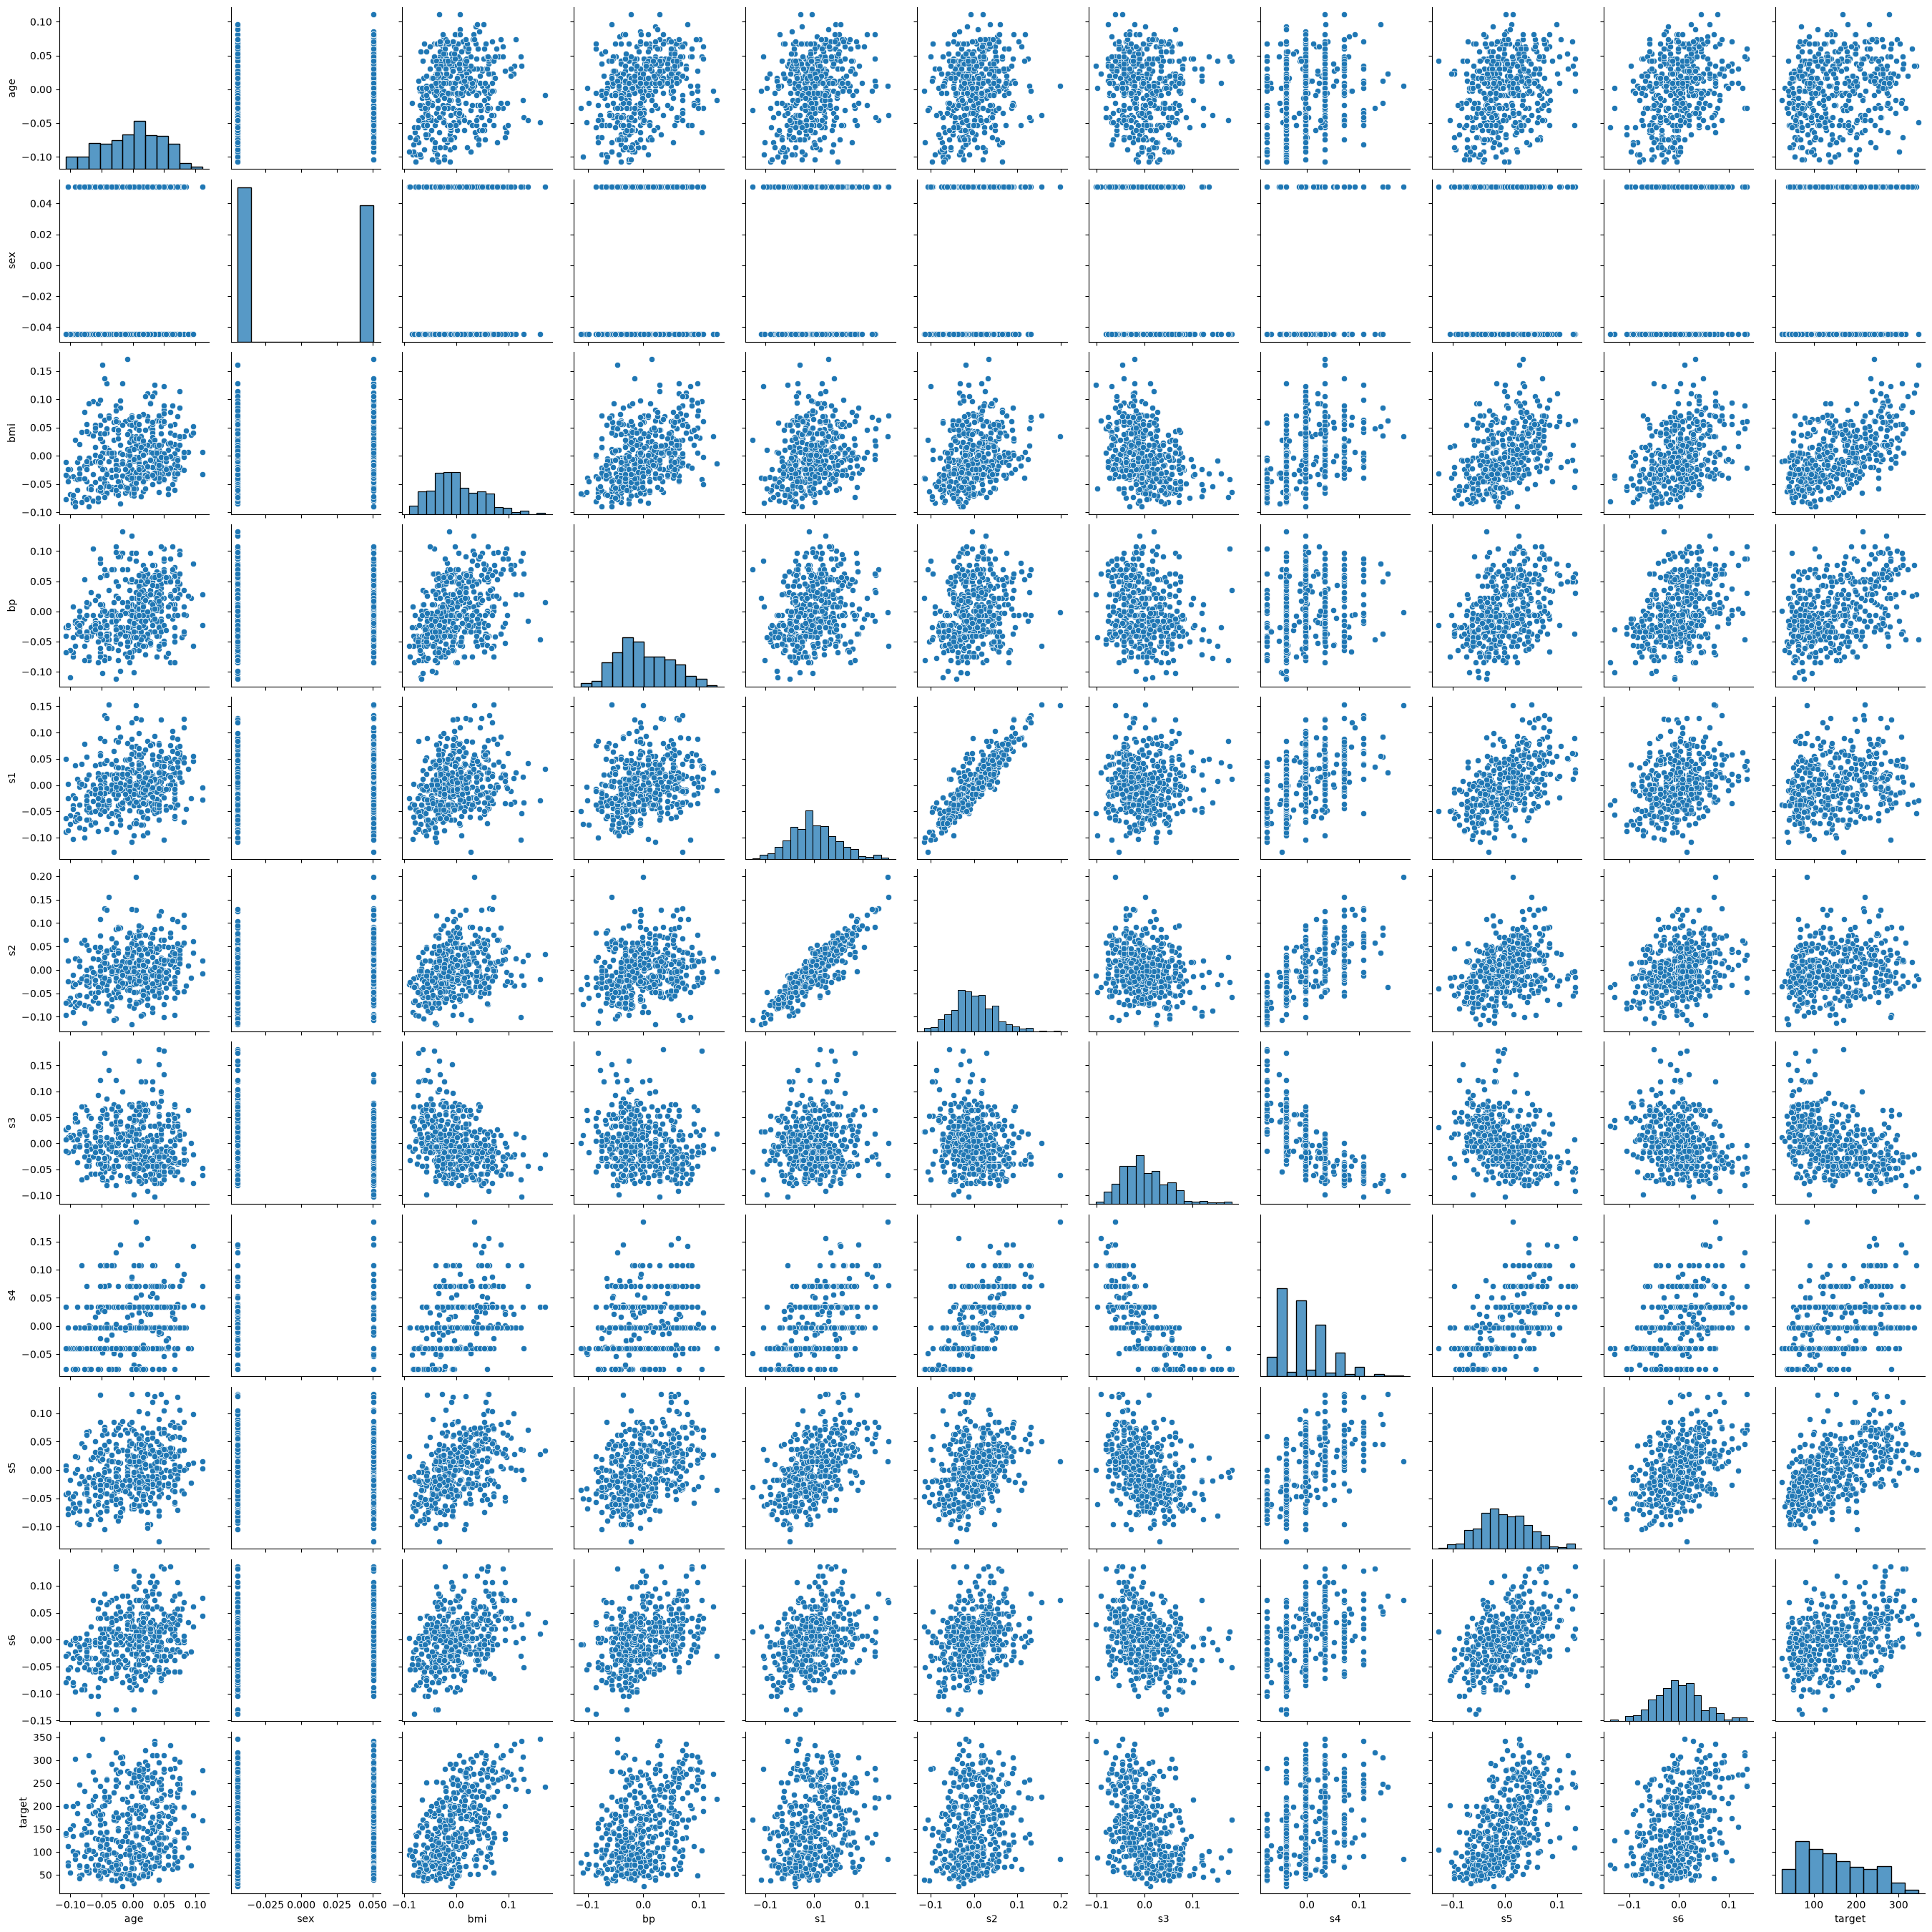

In [11]:
diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target

data = pd.DataFrame(X, columns=diabetes.feature_names)
data['target'] = y

dropping_columns = False
if dropping_columns:
    columns_to_drop = ["sex", "s4"]
    for column in columns_to_drop:
        if column in data.columns:
            data = data.drop(columns = column)

plt.figure(figsize = (10, 10))
sns.heatmap(data.corr(), annot = True)
sns.pairplot(data)

In [12]:
from sklearn.feature_selection import f_regression, SelectKBest

diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target
feature_names = diabetes.feature_names

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for k_val in range(1, 8):
    select_k = SelectKBest(score_func=f_regression, k=k_val)
    select_k.fit(X_train, y_train)
    X_k_train = select_k.transform(X_train)
    X_k_test = select_k.transform(X_test)

    lr_k = LinearRegression().fit(X_k_train, y_train)
    r2_score = lr_k.score(X_k_test, y_test)
    print(f"R-squared score with {k_val} features: {r2_score:.4f}")
    # Print the selected feature indices and their corresponding scores
    selected_indices = select_k.get_support(indices=True)
    scores = select_k.scores_[selected_indices]
    print(f"Selected feature indices: {selected_indices}")
    print(f"Selected feature names: {', '.join([feature_names[i] for i in selected_indices])}")
    print(f"Corresponding scores: {scores}")


R-squared score with 1 features: 0.2334
Selected feature indices: [2]
Selected feature names: bmi
Corresponding scores: [202.38696481]
R-squared score with 2 features: 0.4523
Selected feature indices: [2 8]
Selected feature names: bmi, s5
Corresponding scores: [202.38696481 153.96780617]
R-squared score with 3 features: 0.4543
Selected feature indices: [2 3 8]
Selected feature names: bmi, bp, s5
Corresponding scores: [202.38696481  86.55803837 153.96780617]
R-squared score with 4 features: 0.4526
Selected feature indices: [2 3 7 8]
Selected feature names: bmi, bp, s4, s5
Corresponding scores: [202.38696481  86.55803837  77.41711822 153.96780617]
R-squared score with 5 features: 0.4527
Selected feature indices: [2 3 7 8 9]
Selected feature names: bmi, bp, s4, s5, s6
Corresponding scores: [202.38696481  86.55803837  77.41711822 153.96780617  63.10230381]
R-squared score with 6 features: 0.4468
Selected feature indices: [2 3 6 7 8 9]
Selected feature names: bmi, bp, s3, s4, s5, s6
Corresp

### Scaling

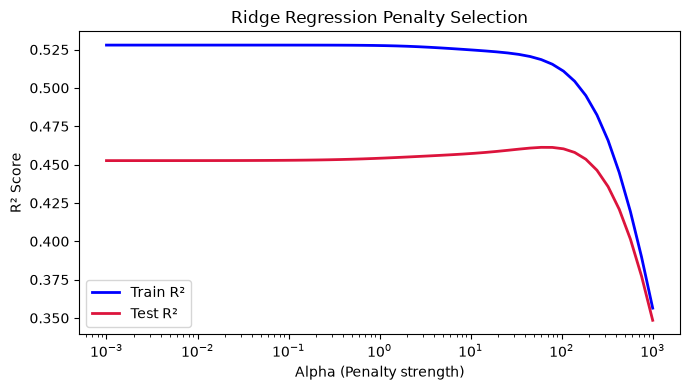

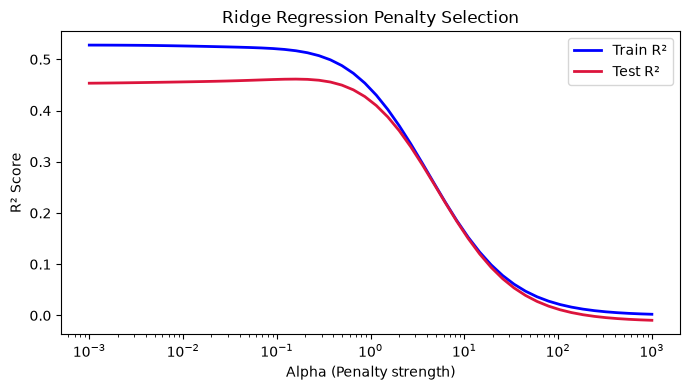

In [13]:
from sklearn.preprocessing import StandardScaler

diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target
feature_names = diabetes.feature_names

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

# Fit the StandardScaler on the training data only, then transform both training
# and test sets using the scaler. Repeat all the steps above and note how the results
# change. Can you explain what happens?

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

alphas = np.logspace(-3, 3, 50)
train_scores = []
test_scores = []
for a in alphas:
    r = Ridge(alpha=a).fit(X_train_scaled, y_train)
    train_scores.append(r.score(X_train_scaled, y_train));
    test_scores.append(r.score(X_test_scaled, y_test));

plt.figure(figsize=(7, 4));
plt.plot(alphas, train_scores, label='Train R²', color='blue', lw=2);
plt.plot(alphas, test_scores, label='Test R²', color='crimson', lw=2);
plt.xscale('log');
plt.xlabel('Alpha (Penalty strength)');
plt.ylabel('R² Score');
plt.title('Ridge Regression Penalty Selection');
plt.legend();
plt.tight_layout()
plt.show()

alphas = np.logspace(-3, 3, 50)
train_scores = []
test_scores = []
for a in alphas:
    r = Ridge(alpha=a).fit(X_train, y_train)
    train_scores.append(r.score(X_train, y_train));
    test_scores.append(r.score(X_test, y_test));

plt.figure(figsize=(7, 4));
plt.plot(alphas, train_scores, label='Train R²', color='blue', lw=2);
plt.plot(alphas, test_scores, label='Test R²', color='crimson', lw=2);
plt.xscale('log');
plt.xlabel('Alpha (Penalty strength)');
plt.ylabel('R² Score');
plt.title('Ridge Regression Penalty Selection');
plt.legend();
plt.tight_layout()
plt.show()





# Exercise 3 (Feature Selection). 

Load the California Housing dataset and inject artificial
noise into it: generate 20 new columns of purely random numerical data and append
them as new features. After that, split the amended data into training and test sets.

1. Fit a baseline linear regression model on this noisy dataset and record the test R2
.

2. Now select the top 8 features based on their correlations with the target. Fit a new
linear regression model on these 8 features. How does the test R2
change? Are any
of your “noise” features in the selection?

3. Try to choose a different number of features and repeat the previous step. Can
you think of a reasonable way to determine the number of features? Does your
approach improve performance?

4. (optional) Select the top 8 features based on the fitted baseline model and use them.
Are they the same you selected before?

5. Use Recursive Feature Elimination RFE from scikit-learn to select 8 features.

6. Fit a LASSO regression and tune α until it selects roughly 8 features (features with
non-zero coefficients).

7. Which of the methods above resulted in the highest test R2
, and which was most
robust to the artificial noise?

## Response

### Load the California Housing Dataset

In [ ]:
from sklearn.datasets import fetch_california_housing

# Load the california housing dataset and split it into training and test sets.

california = fetch_california_housing(data_home="../../scikit_learn_data", download_if_missing=False)
X = california.data
y = california.target

for i in range(0, 20):
    # Generate synthetic data with the same number of samples as the california housing dataset
    synthetic_data = np.random.normal(0, 1, size=len(X))
    X = np.column_stack((X, synthetic_data))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Fit a Baseline LR Model on the noisy dataset

In [26]:
ls_base = LinearRegression().fit(X_train, y_train)
# Print the R2 score of the base model on the test data
print("Base Model R-squared:", ls_base.score(X_test, y_test))

Base Model R-squared: 0.5766353927682717


In [28]:
# Select the top 8 features using SelectKBest and f_regression, fit a linear regression model to the training data, and evaluate its performance on the test data.
select_k = SelectKBest(score_func=f_regression, k=8)
select_k.fit(X_train, y_train)
X_k_train = select_k.transform(X_train)
X_k_test = select_k.transform(X_test)
ls_k = LinearRegression().fit(X_k_train, y_train)
# Print the R2 score of the model with selected features on the test data
print("Selected Features Model R-squared:", ls_k.score(X_k_test, y_test))
# Print the selected feature indices and their corresponding scores
selected_indices = select_k.get_support(indices=True)
scores = select_k.scores_[selected_indices]
print(f"Selected feature indices: {selected_indices}")
print(f"Selected feature names: {', '.join([california.feature_names[i] for i in selected_indices])}")
print(f"Corresponding scores: {scores}")

Selected Features Model R-squared: 0.5757877060324512
Selected feature indices: [0 1 2 3 4 5 6 7]
Selected feature names: MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude
Corresponding scores: [1.50574391e+04 1.79495552e+02 4.25373449e+02 4.36507148e+01
 1.11961694e+01 8.01650853e+00 3.44579030e+02 3.55434501e+01]


### Recursive Feature Elimination

### Fit and Tune a LASSO Regression

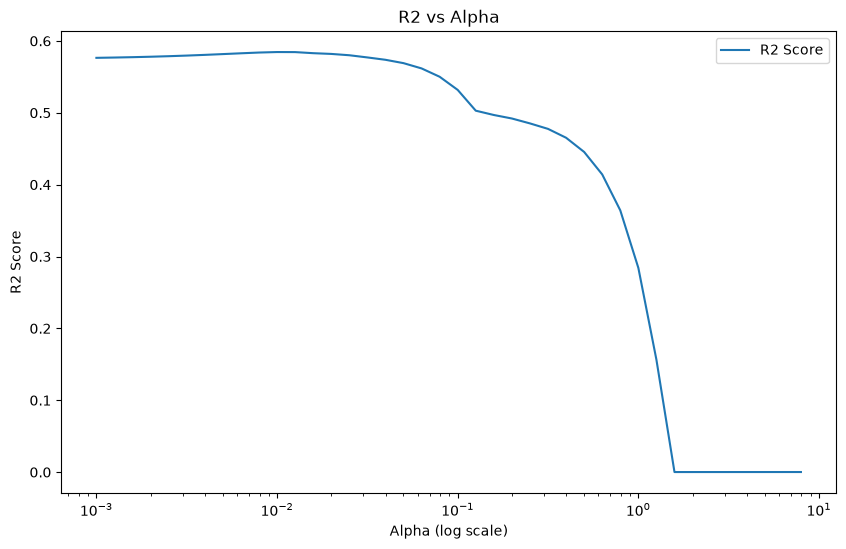

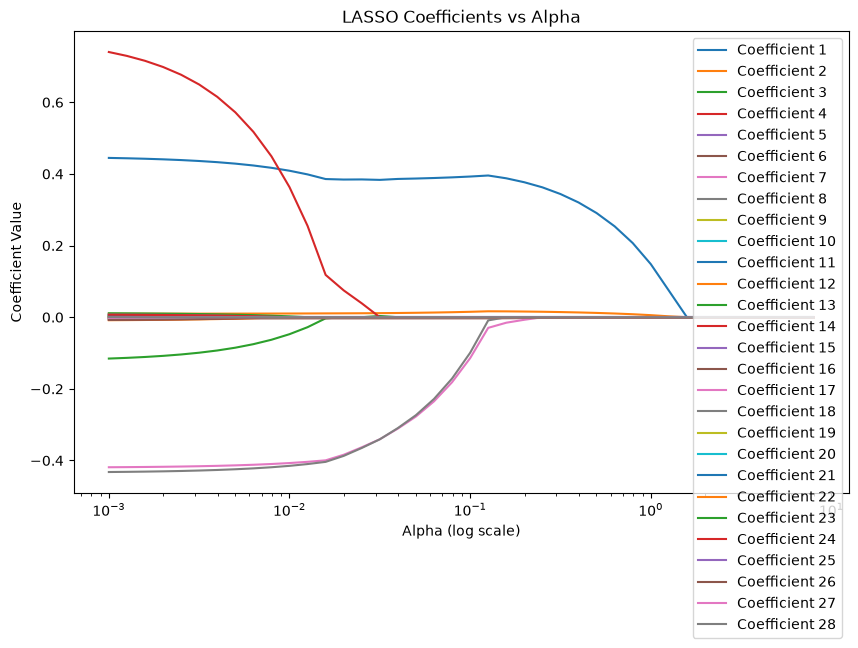

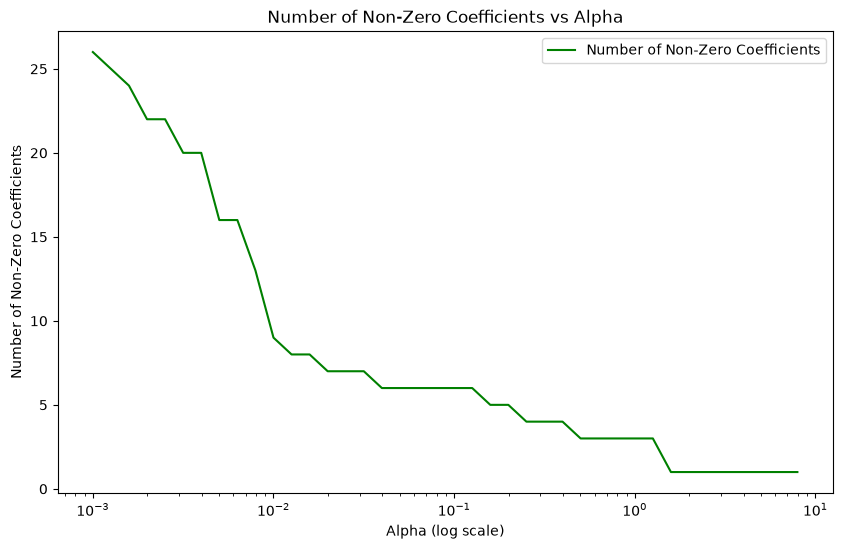

Number of Non-Zero Coefficients and Corresponding Alpha Values:
[[2.60000000e+01 1.00000000e-03]
 [2.50000000e+01 1.25892541e-03]
 [2.40000000e+01 1.58489319e-03]
 [2.20000000e+01 1.99526231e-03]
 [2.20000000e+01 2.51188643e-03]
 [2.00000000e+01 3.16227766e-03]
 [2.00000000e+01 3.98107171e-03]
 [1.60000000e+01 5.01187234e-03]
 [1.60000000e+01 6.30957344e-03]
 [1.30000000e+01 7.94328235e-03]
 [9.00000000e+00 1.00000000e-02]
 [8.00000000e+00 1.25892541e-02]
 [8.00000000e+00 1.58489319e-02]
 [7.00000000e+00 1.99526231e-02]
 [7.00000000e+00 2.51188643e-02]
 [7.00000000e+00 3.16227766e-02]
 [6.00000000e+00 3.98107171e-02]
 [6.00000000e+00 5.01187234e-02]
 [6.00000000e+00 6.30957344e-02]
 [6.00000000e+00 7.94328235e-02]
 [6.00000000e+00 1.00000000e-01]
 [6.00000000e+00 1.25892541e-01]
 [5.00000000e+00 1.58489319e-01]
 [5.00000000e+00 1.99526231e-01]
 [4.00000000e+00 2.51188643e-01]
 [4.00000000e+00 3.16227766e-01]
 [4.00000000e+00 3.98107171e-01]
 [3.00000000e+00 5.01187234e-01]
 [3.00000000

In [37]:
from sklearn.datasets import fetch_california_housing

# Load the california housing dataset and split it into training and test sets.

california = fetch_california_housing(data_home="../../scikit_learn_data", download_if_missing=False)
X = california.data
y = california.target

for i in range(0, 20):
    # Generate synthetic data with the same number of samples as the california housing dataset
    synthetic_data = np.random.normal(0, 1, size=len(X))
    X = np.column_stack((X, synthetic_data))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

alpha_vals = []
r2_vals = []
y_vals = []
num_non_zero_coefs = []
for i in range(-30, 10, 1):
    alpha = 10 ** (i/10)
    lasso_model = Lasso(alpha=alpha).fit(X_train, y_train)
    alpha_vals.append(alpha)
    # Get the R-squared score of the Lasso model on the test data
    r2_score = lasso_model.score(X_test, y_test)
    r2_vals.append(r2_score)
    y_vals.append(lasso_model.coef_)
    # Count the number of non-zero coefficients
    num_non_zero_coefs.append(np.sum(lasso_model.coef_ != 0))

# Plot the R-squared scores of the Lasso model for different alpha values
plt.figure(figsize=(10, 6))
plt.plot(alpha_vals, r2_vals, label=f'R2 Score')
    
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('R2 Score')
plt.title('R2 vs Alpha')
plt.legend()
plt.show()

# Plot the coefficients of the LASSO model for different alpha values
plt.figure(figsize=(10, 6))
for i in range(len(y_vals[0])):
    plt.plot(alpha_vals, [y[i] for y in y_vals], label=f'Coefficient {i+1}')
    
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Coefficient Value')
plt.title('LASSO Coefficients vs Alpha')
plt.legend()
plt.show()

# Plot the number of non-zero coefficients of the LASSO model for different alpha values
plt.figure(figsize=(10, 6))
plt.plot(alpha_vals, num_non_zero_coefs, label='Number of Non-Zero Coefficients', color='green')
plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Number of Non-Zero Coefficients')
plt.title('Number of Non-Zero Coefficients vs Alpha')
plt.legend()
plt.show()

tmp = np.array(num_non_zero_coefs)
tmp = np.stack((tmp, alpha_vals), axis=1)
print("Number of Non-Zero Coefficients and Corresponding Alpha Values:")
print(tmp)

tmp2 = np.array(r2_vals)
tmp2 = np.stack((tmp2, alpha_vals), axis=1)
print("R2 Scores and Corresponding Alpha Values:")
print(tmp2)




# Exercise 4 (Elastic Net). 

Create a synthetic dataset with 1000 instances and the following features: x1, x2 and x3 are independent standard normal variables (that is, with
a mean of 0 and a standard deviation of 1); x4, x5 and x6 are x1 with a tiny amount of
additional noise (say, having standard deviation of 0.02); x7 and x8 are x3 also with a
tiny amount of additional noise; the target y is a linear function of x1 and x2 with a small
amount of additional noise (say, having standard deviation of 0.1). Hence your target will
depend on the group of 5 features x1, x2, x4, x5 and x6, where 4 are highly correlated,
and will be independent of the remaining 3, also highly correlated to each other.

1. Fit a Lasso model with alpha=1 and inspect the coefficients for the features. Do
they agree with your data-generating model?

2. Fit a Ridge model with alpha=1 and inspect the coefficients. How do they compare
to the coefficients for LASSO?

3. Fit an ElasticNet model with alpha=1 and l1_ratio=0.5 and inspect the coefficients. Do you get a better representation of your data-generating model?

4. (open-ended investigation) Try different values of the regularisation parameters.
Then repeat the exercise for different amounts of noise when the features and target
are generated (try to find when the models break).